In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
import cv2
import numpy as np
import imutils
import random
import pickle

In [2]:
data_dir = Path.cwd() / "EnsembleA"
print(data_dir)
LABELS = ["Cercle2", "Cercle3", "Cercle4", "Cercle5", "Diamant2", "Diamant3", "Diamant4", "Diamant5", "Hexagone2", "Hexagone3", "Hexagone4", "Hexagone5", "Triangle2", "Triangle3", "Triangle4", "Triangle5"]

/home/mathd/LOG635-Labo2/EnsembleA


## Choix du sous-ensemble B et redimensionnement des images

In [3]:
# Image resize
WIDTH = 160
HEIGHT = 120

data_set = []

for first_level in data_dir.glob('*'):
    if first_level.is_dir() and not first_level.name.startswith('.'):
        for second_level in first_level.glob("*"):
            if second_level.is_dir() and not second_level.name.startswith('.'):
                label = Path(second_level).name
                if label in LABELS:
                    class_num = LABELS.index(label)
                    for file in second_level.glob("*.jpg"):
                        image = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
                        data_set.append([image, class_num, label])

In [4]:
data_setB = []
for image in data_set:
    if image[1] in [0,3,4,7,8,11,12,15]:
        data_setB.append(image)

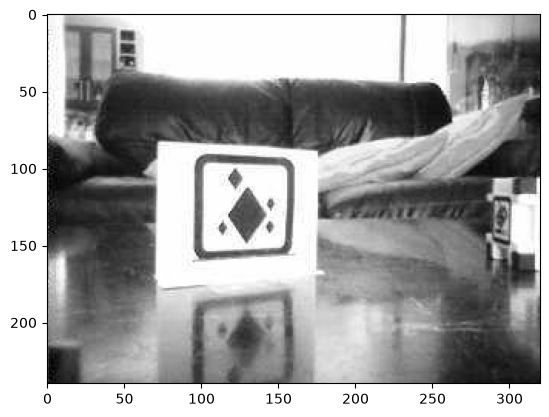

In [5]:
plt.imshow(data_setB[40][0], cmap="gray")

## Détection de la ROI

In [6]:
def detect_shape(contour):
    # initialize the shape name and approximate the contour
    shape = "unidentified"
    peri = cv2.arcLength(contour, True)
    approx = cv2.approxPolyDP(contour, 0.04 * peri, True)
    
    # if the shape is a triangle, it will have 3 vertices
    if len(approx) == 3:
        shape = "triangle"

    # if the shape has 4 vertices, it is either a square or
    # a rectangle
    elif len(approx) == 4:
        # compute the bounding box of the contour and use the
        # bounding box to compute the aspect ratio
        (x, y, w, h) = cv2.boundingRect(approx)
        ar = w / float(h)

        # a square will have an aspect ratio that is approximately
        # equal to one, otherwise, the shape is a rectangle
        shape = "square" if ar >= 0.95 and ar <= 1.05 else "diamond"

    # if the shape is a pentagon, it will have 5 vertices
    elif len(approx) == 5:
        shape = "hexagon"

    # otherwise, we assume the shape is a circle
    else:
        shape = "circle"

    # return the name of the shape
    return shape

### Extraction de la ROI

Chaque image est seuillée, puis on cherche le cadre noir du marqueur parmi ses contours. Un contour est retenu s'il est à peu près carré (20 à 110 px), loin du bord, et s'il entoure un intérieur clair contenant une forme pleine. Cela rejette les grandes formes noires et les symboles des cubes.

Le meilleur candidat est redimensionné en 64×64, et son nombre de motifs et son écart-type sont conservés. Les images sans marqueur sont ignorées.

In [7]:
ROI_TAILLE = 64
COTE_MIN = 20
COTE_MAX = 110
RATIO_CARRE_MIN = 0.82
RATIO_CARRE_MAX = 1.22
SOMMETS_MIN = 4
SOMMETS_MAX = 8
RATIO_TROU_MIN = 0.35
RATIO_TROU_MAX = 0.82
ECART_TYPE_MIN = 18
AIRE_MOTIF_MIN = 8
CONTRASTE_MIN = 40
SOLIDITE_MIN = 0.8

HIERARCHIE_SUIVANT = 0
HIERARCHIE_PREMIER_ENFANT = 2
AUCUN_CONTOUR = -1


def touche_le_bord(image, x, y, w, h):
    hauteur_image, largeur_image = image.shape
    if x <= 1 or y <= 1:
        return True
    if x + w >= largeur_image - 1:
        return True
    if y + h >= hauteur_image - 1:
        return True
    return False


def a_une_taille_valide(w, h):
    largeur_valide = COTE_MIN <= w <= COTE_MAX
    hauteur_valide = COTE_MIN <= h <= COTE_MAX
    return largeur_valide and hauteur_valide


def est_presque_carre(w, h):
    ratio = w / h
    return RATIO_CARRE_MIN <= ratio <= RATIO_CARRE_MAX


def a_un_nombre_de_sommets_valide(contour):
    perimetre = cv2.arcLength(contour, True)
    sommets = cv2.approxPolyDP(contour, 0.04 * perimetre, True)
    return SOMMETS_MIN <= len(sommets) <= SOMMETS_MAX


def trou_a_une_taille_valide(contour_trou, w, h):
    x_trou, y_trou, largeur_trou, hauteur_trou = cv2.boundingRect(contour_trou)
    aire_trou = largeur_trou * hauteur_trou
    aire_cadre = w * h
    ratio = aire_trou / aire_cadre
    return RATIO_TROU_MIN <= ratio <= RATIO_TROU_MAX


def remplir_contour(image, contour):
    masque = np.zeros(image.shape, np.uint8)
    cv2.drawContours(masque, [contour], -1, 255, -1)
    return masque


def interieur_est_plus_clair(image, masque_trou, masque_anneau):
    pixels_interieur = image[masque_trou > 0]
    pixels_cadre = image[masque_anneau > 0]
    clarte_interieur = np.percentile(pixels_interieur, 90)
    clarte_cadre = np.median(pixels_cadre)
    contraste = clarte_interieur - clarte_cadre
    return contraste >= CONTRASTE_MIN


def calculer_solidite(image, masque_trou):
    noyau = np.ones((3, 3), np.uint8)
    masque_reduit = cv2.erode(masque_trou, noyau)
    est_interieur = masque_reduit > 0

    pixels_interieur = image[est_interieur]
    if pixels_interieur.size < 20:
        return 0

    pixels_en_colonne = pixels_interieur.reshape(-1, 1)
    seuil, _ = cv2.threshold(pixels_en_colonne, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    est_sombre = image < seuil
    zones_sombres = np.zeros(image.shape, np.uint8)
    zones_sombres[est_interieur & est_sombre] = 255

    formes, _ = cv2.findContours(zones_sombres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(formes) == 0:
        return 0

    plus_grande_forme = max(formes, key=cv2.contourArea)
    enveloppe = cv2.convexHull(plus_grande_forme)
    aire_enveloppe = cv2.contourArea(enveloppe)
    if aire_enveloppe == 0:
        return 0

    aire_forme = cv2.contourArea(plus_grande_forme)
    return aire_forme / aire_enveloppe


def compter_motifs(contours, hierarchie, indice_trou):
    nombre_motifs = 0
    indice_motif = hierarchie[indice_trou][HIERARCHIE_PREMIER_ENFANT]

    while indice_motif != AUCUN_CONTOUR:
        aire_motif = cv2.contourArea(contours[indice_motif])
        if aire_motif > AIRE_MOTIF_MIN:
            nombre_motifs += 1
        indice_motif = hierarchie[indice_motif][HIERARCHIE_SUIVANT]

    return nombre_motifs


def evaluer_cadre(image, contours, hierarchie, indice_contour):
    contour = contours[indice_contour]
    x, y, w, h = cv2.boundingRect(contour)

    if touche_le_bord(image, x, y, w, h):
        return None
    if not a_une_taille_valide(w, h):
        return None
    if not est_presque_carre(w, h):
        return None
    if not a_un_nombre_de_sommets_valide(contour):
        return None

    indice_trou = hierarchie[indice_contour][HIERARCHIE_PREMIER_ENFANT]
    if indice_trou == AUCUN_CONTOUR:
        return None

    contour_trou = contours[indice_trou]
    if not trou_a_une_taille_valide(contour_trou, w, h):
        return None

    zone_cadre = image[y:y + h, x:x + w]
    ecart_type = np.std(zone_cadre)
    if ecart_type < ECART_TYPE_MIN:
        return None

    masque_cadre = remplir_contour(image, contour)
    masque_trou = remplir_contour(image, contour_trou)
    masque_anneau = cv2.subtract(masque_cadre, masque_trou)
    if not masque_anneau.any():
        return None
    if not interieur_est_plus_clair(image, masque_trou, masque_anneau):
        return None
    if calculer_solidite(image, masque_trou) < SOLIDITE_MIN:
        return None

    nombre_motifs = compter_motifs(contours, hierarchie, indice_trou)
    return {"x": x, "y": y, "w": w, "h": h, "nb_motifs": nombre_motifs, "ecart_type": ecart_type}


def score_candidat(candidat):
    return candidat["nb_motifs"] * 100 + candidat["ecart_type"]


def trouver_contours(image):
    image_floue = cv2.GaussianBlur(image, (3, 3), 0)
    image_seuillee = cv2.adaptiveThreshold(
        image_floue, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 3
    )
    return cv2.findContours(image_seuillee, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)


def decouper_roi(image, candidat):
    haut = max(0, candidat["y"] - 1)
    gauche = max(0, candidat["x"] - 1)
    bas = candidat["y"] + candidat["h"] + 1
    droite = candidat["x"] + candidat["w"] + 1
    roi = image[haut:bas, gauche:droite]
    return cv2.resize(roi, (ROI_TAILLE, ROI_TAILLE))


def extraire_roi(image):
    contours, hierarchie = trouver_contours(image)
    if hierarchie is None:
        return None

    hierarchie = hierarchie[0]
    candidats = []
    for indice_contour in range(len(contours)):
        candidat = evaluer_cadre(image, contours, hierarchie, indice_contour)
        if candidat is not None:
            candidats.append(candidat)

    if len(candidats) == 0:
        return None

    meilleur = max(candidats, key=score_candidat)
    roi = decouper_roi(image, meilleur)
    return roi, meilleur["nb_motifs"], meilleur["ecart_type"]


data_setROI = []
for image, class_num, nom_classe in data_setB:
    resultat = extraire_roi(image)
    if resultat is None:
        continue

    roi, nb_motifs, ecart_type = resultat
    data_setROI.append([roi, nb_motifs, ecart_type, class_num])

print(f"{len(data_setROI)} images conservées sur {len(data_setB)}")

1566 images conservées sur 2371


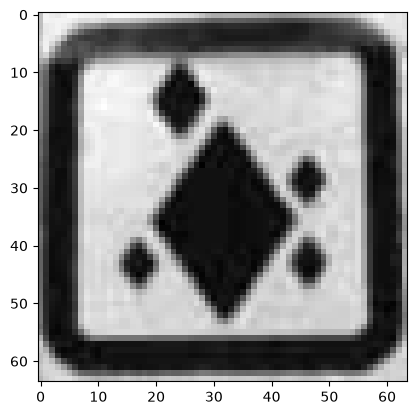

In [8]:
plt.imshow(data_setROI[10][0], cmap="gray")

In [9]:
import numpy as np
import pickle

X1 = []
y1 = []

for item in data_setROI:
    image = item[0]
    nb_motifs = item[1] # Assurez-vous de l'avoir ajouté dans data_setROI
    std_dev = item[2]   # Pareil ici
    label = item[3]
    
    # 1. Aplatir l'image (64x64 -> 4096)
    image_flattened = image.flatten()
    
    # 2. Concaténer l'image aplatie avec les 2 caractéristiques (taille finale: 4098)
    features = np.append(image_flattened, [nb_motifs, std_dev])
    
    X1.append(features)
    y1.append(label)

# Conversion en tableaux Numpy pour optimiser les calculs matriciels futurs
X1 = np.array(X1)
y1 = np.array(y1)

# 3. Sauvegarde dans des fichiers .pickle
with open("X1.pickle", "wb") as f:
    pickle.dump(X1, f)

with open("y1.pickle", "wb") as f:
    pickle.dump(y1, f)

print(f"Sauvegarde terminée ! Dimensions de X1 : {X1.shape}")

Sauvegarde terminée ! Dimensions de X1 : (1566, 4098)
